# Fig. 8a: configuration coordinate diagrams of Bi$_{Cd}$ + Bi$_{Se}$

This notebook reproduces Fig. 8a of the DefectNet paper from scratch: the configuration coordinate (CC) diagrams of
the Bi$_{Cd}$ + Bi$_{Se}$ complex in CdSe$_{0.06}$Te$_{0.94}$ for its four levels in the HSE06 gap, the classical
capture barriers, and the local structure of the Bi$_{Cd}$ site against DFT. Everything is computed here with
DefectNet (PBEsol head) from the DFT input structures of the five charge states. It takes about 20 minutes on one GPU.

Open this notebook from the `examples/paper/` folder of the repository. The DFT data it needs are in `data/` as
Apache Arrow tables (see `README.md` in this folder for the columns), and the model is the `DefectNet-v1.0.pt` weights file
of the v1.0 release. A GPU is strongly recommended.

## Install and download the model

The cell below installs TACE at commit `057e463` with the patch in `patches/`, the DefectNet package and `pyarrow`,
skipping every step that is already done. Install PyTorch for your machine first (pytorch.org). The weights
(`DefectNet-v1.0.pt`, 891 MB) are downloaded with the GitHub command-line tool unless a copy is already here or in
`examples/`.

In [1]:
%%bash
cd ../..                                         # repository root
if python -c "import tace" 2>/dev/null; then echo "TACE is already installed"
else
  git clone -q https://github.com/xvzemin/tace.git ../tace
  git -C ../tace checkout -q 057e463
  git -C ../tace apply "$PWD/patches/tace-057e463.patch"
  pip install -q -e ../tace
fi
python -c "import defectnet" 2>/dev/null && echo "DefectNet is already installed" || pip install -q -e .
python -c "import pyarrow" 2>/dev/null && echo "pyarrow is already installed" || pip install -q pyarrow
cd examples/paper
if [ -f DefectNet-v1.0.pt ]; then echo "DefectNet-v1.0.pt is already here"
elif [ -f ../DefectNet-v1.0.pt ]; then ln -s ../DefectNet-v1.0.pt . && echo "using ../DefectNet-v1.0.pt"
else gh release download v1.0 -R msehabibur/DefectNet -p DefectNet-v1.0.pt; fi

TACE is already installed


DefectNet is already installed


pyarrow is already installed


DefectNet-v1.0.pt is already here


## Load the model and the data

Every row of an Arrow table is one DFT calculation. `atoms(row)` builds the ASE structure the benchmark started from
(the DFT input geometry of a defect cell, the DFT final geometry of a pristine cell), and `seed(row)` is the random
seed of its rattle, the CRC32 checksum of the row's `path`, so a relaxation here starts from exactly the same
displaced atoms as in the paper. GPU arithmetic is not bit-for-bit reproducible across devices, so energies can
differ from the paper values by a few meV.

In [2]:
import logging
import warnings
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)                 # hides TACE's start-up notes

import zlib
import numpy as np
import matplotlib.pyplot as plt
import pyarrow.feather as feather
from ase import Atoms

import defectnet as dn


def table(name):
    return feather.read_table(f"data/{name}.arrow").to_pylist()


def atoms(row, positions="start_positions"):
    return Atoms(row["start_symbols"], positions=row[positions], cell=row["start_cell"], pbc=True)


def seed(row):
    return zlib.crc32(row["path"].encode())


calc = dn.load("DefectNet-v1.0.pt", functional="PBEsol")
cells = table("fig6a_cells")
pristine = {r["path"]: r for r in table("pristine_pbesol")}
print(len(cells), "defect cells and", len(pristine), "pristine cells, PBEsol")

172 defect cells and 15 pristine cells, PBEsol


## The five charge states

Each charge state is first relaxed as in the benchmark of Fig. 6 (rattled start, FIRE to 0.02 eV/Å), then
relaxed tightly with LBFGS to 0.002 eV/Å, so that the minima are accurate enough for the curvature of the CC
curves. The cell stays at the DFT lattice.

In [3]:
from ase.optimize import LBFGS


def tight(a, q):
    a = dn.charged(a, q)
    a.calc = calc
    LBFGS(a, logfile=None).run(fmax=0.002, steps=3000)
    return a, float(a.get_potential_energy())


cpx = {r["q"]: r for r in cells if r["path"].startswith("DFT/defect/PBEsol/CdSe0.06Te0.94/Bi_Cd+Bi_Se/")}
first, own = {}, {}
for q, r in sorted(cpx.items(), reverse=True):
    first[q] = dn.relax(atoms(r), calc, q=q, seed=seed(r))
    own[q] = tight(first[q], q)
    print(f"q = {q:+d}: FIRE {first[q].info['steps']} steps, tight minimum E = {own[q][1]:.4f} eV")

q = +2: FIRE 72 steps, tight minimum E = -600.9319 eV


q = +1: FIRE 88 steps, tight minimum E = -598.7144 eV


q = +0: FIRE 77 steps, tight minimum E = -596.2737 eV


q = -1: FIRE 71 steps, tight minimum E = -593.6490 eV


q = -2: FIRE 75 steps, tight minimum E = -590.8016 eV


## Local structure against DFT

The lower rows of Fig. 8a compare the Bi$_{Cd}$ site after the benchmark relaxation with the DFT relaxation. Over
the atoms within 5 Å of either Bi atom in the DFT cell, after removing the mean shift $\overline{\Delta\mathbf r}$,

$$\mathrm{RMSD} = \Big[\frac{1}{N}\sum_{i} \big|\Delta\mathbf r_i - \overline{\Delta\mathbf r}\big|^2\Big]^{1/2}.$$

Atom 107 is Bi on the Cd site, and atoms 147 and 189 are the two Te neighbours whose distances the figure gives.

In [4]:
def mic(a, d):
    f = np.linalg.solve(a.cell.T, np.atleast_2d(d).T).T
    return (f - np.round(f)) @ a.cell.array


BI, TE = 107, (147, 189)
print(" q   RMSD (A)   Bi-Te147 DFT / DefectNet   Bi-Te189 DFT / DefectNet")
for q in sorted(cpx, reverse=True):
    A, B = atoms(cpx[q], "dft_positions"), first[q]
    bis = [i for i, s in enumerate(A.get_chemical_symbols()) if s == "Bi"]
    near = np.min([np.linalg.norm(mic(A, A.positions - A.positions[b]), axis=1) for b in bis], axis=0) < 5.0
    dd = mic(A, B.positions - A.positions)
    dd -= dd.mean(0)
    rmsd = np.sqrt((dd[near] ** 2).sum(1).mean())
    dist = lambda X, j: np.linalg.norm(mic(X, X.positions[j] - X.positions[BI]))
    print(f"{q:+d}   {rmsd:.3f}      {dist(A, TE[0]):.2f} / {dist(B, TE[0]):.2f}                "
          f"{dist(A, TE[1]):.2f} / {dist(B, TE[1]):.2f}")

 q   RMSD (A)   Bi-Te147 DFT / DefectNet   Bi-Te189 DFT / DefectNet
+2   0.036      3.00 / 3.00                3.01 / 3.00
+1   0.035      2.99 / 2.99                3.01 / 3.01
+0   0.025      2.98 / 2.98                3.01 / 3.02
-1   0.036      2.98 / 2.97                3.02 / 3.01
-2   0.121      2.98 / 2.97                3.02 / 3.21


## The CC line between two charge states

For each level $(q/q-1)$ the $q-1$ state is also relaxed from the $q$ minimum, and that minimum replaces the
$q-1$ minimum found above only if it is lower by more than 1 meV, the size of the numerical noise between GPUs. For this
complex the second relaxation is never lower by more than that, so the lines run between the minima found above, as in
the paper. With the mass-weighted rigid translation removed from the displacements $\Delta\mathbf r_i$ between the two
minima,

$$\Delta Q = \Big(\sum_i m_i |\Delta\mathbf r_i|^2\Big)^{1/2}, \qquad \mathbf R(Q) = \mathbf R_q + \frac{Q}{\Delta Q}\,\Delta\mathbf r,$$

and both charge states are evaluated on the straight line from $Q = -30$ to 40 amu$^{1/2}$ Å in steps of 1,
plus the two minima.

In [5]:
def energy(A, pos, q):
    b = dn.charged(A, q)
    b.positions = pos
    b.calc = calc
    return float(b.get_potential_energy())


lines = []
for q in (2, 1, 0, -1):
    A = own[q][0]
    B, eB = own[q - 1]
    C, eC = tight(A, q - 1)
    if eC < eB - 0.001:
        B, eB = C, eC
    print(f"q - 1 = {q - 1:+d} relaxed from the q minimum: {eC - own[q - 1][1]:+.4f} eV against its own minimum")
    m = A.get_masses()
    d = mic(A, B.positions - A.positions)
    d -= (m[:, None] * d).sum(0) / m.sum()
    dQ = float(np.sqrt((m[:, None] * d ** 2).sum()))
    Q = np.unique(np.concatenate([np.arange(-30.0, 40.0001, 1.0), [0.0, dQ]]))
    Eq = np.array([energy(A, A.positions + x / dQ * d, q) for x in Q])
    Em = np.array([energy(A, A.positions + x / dQ * d, q - 1) for x in Q])
    lines.append(dict(q=q, dQ=dQ, Q=Q, Eq=Eq, Em=Em, dmax=float(np.linalg.norm(d, axis=1).max())))
    print(f"({q:+d}/{q - 1:+d}): dQ = {dQ:.2f} amu^1/2 A, largest atomic shift {lines[-1]['dmax']:.2f} A")

q - 1 = +1 relaxed from the q minimum: +0.0000 eV against its own minimum


(+2/+1): dQ = 1.82 amu^1/2 A, largest atomic shift 0.06 A


q - 1 = +0 relaxed from the q minimum: +0.0000 eV against its own minimum


(+1/+0): dQ = 2.10 amu^1/2 A, largest atomic shift 0.06 A


q - 1 = -1 relaxed from the q minimum: +0.0000 eV against its own minimum


(+0/-1): dQ = 1.06 amu^1/2 A, largest atomic shift 0.02 A


q - 1 = -2 relaxed from the q minimum: +0.0179 eV against its own minimum


(-1/-2): dQ = 8.90 amu^1/2 A, largest atomic shift 0.48 A


## Levels, curves and capture barriers

The level is taken from the energies at the two minima and placed on the HSE06 band edges of Fig. 7:

$$\varepsilon(q/q-1) = \big[E_{q-1}(\Delta Q) - E_q(0) - E_{VBM}^{PBEsol}\big] - \big(E_{VBM}^{HSE} - E_{VBM}^{PBEsol}\big).$$

The three curves are D$^q$ (zero at its minimum), D$^{q-1}$ + h (its minimum at $\varepsilon$) and D$^q$ + e + h
(D$^q$ raised by the HSE06 gap $E_g$). Electron capture D$^q$ + e → D$^{q-1}$ goes over the crossing of the top two
curves, and hole capture D$^{q-1}$ + h → D$^q$ over the crossing of the lower two, each barrier measured from the
minimum of the starting curve (Alkauskas, Yan and Van de Walle, Phys. Rev. B 90, 075202 (2014)). When two curves do
not cross inside the sampled range, the barrier is at least the height of the starting curve at the nearer end.

(+2/+1): eps 0.51 eV, dQ 1.82, electron capture > 4.12 eV, hole capture > 4.66 eV   (paper: eps 0.51 eV, dQ 1.82; every barrier above 2.1 eV)
(+1/+0): eps 0.73 eV, dQ 2.10, electron capture > 2.67 eV, hole capture > 3.21 eV   (paper: eps 0.73 eV, dQ 2.10; every barrier above 2.1 eV)
(+0/-1): eps 0.91 eV, dQ 1.06, electron capture > 2.16 eV, hole capture > 2.22 eV   (paper: eps 0.91 eV, dQ 1.06; every barrier above 2.1 eV)
(-1/-2): eps 1.14 eV, dQ 8.90, electron capture > 2.83 eV, hole capture > 2.52 eV   (paper: eps 1.14 eV, dQ 8.90; every barrier above 2.1 eV)


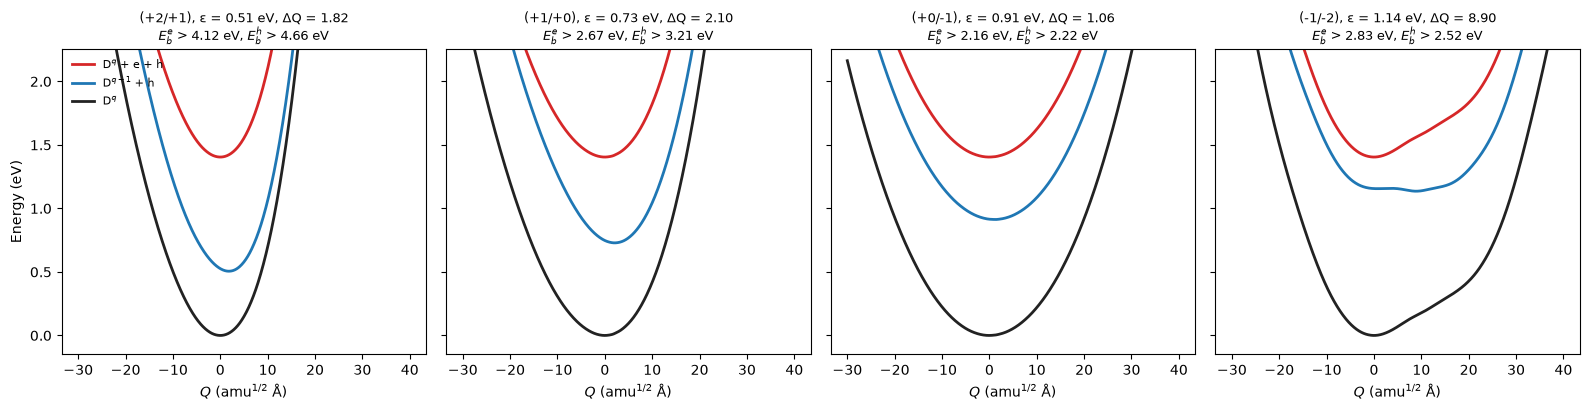

In [6]:
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq

P = pristine[cpx[0]["pristine"]]
VBM_P, VBM_H, GAP = P["vbm"], 1.7118, 1.4045           # PBEsol VBM of the pristine cell; HSE06 VBM and gap (Fig. 7)
PAPER = {2: (0.51, 1.82), 1: (0.73, 2.10), 0: (0.91, 1.06), -1: (1.14, 8.90)}


def crossings(f, g, lo, hi):
    x = np.linspace(lo, hi, 8001)
    s = np.sign(f(x) - g(x))
    return [brentq(lambda t: f(t) - g(t), x[i], x[i + 1]) for i in np.nonzero(np.diff(s))[0]]


fig, axs = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
for ax, L in zip(axs, lines):
    Q, i0, i1 = L["Q"], np.argmin(np.abs(L["Q"])), np.argmin(np.abs(L["Q"] - L["dQ"]))
    eps = (L["Em"][i1] - L["Eq"][i0] - VBM_P) - (VBM_H - VBM_P)
    Y, X = L["Eq"] - L["Eq"][i0], L["Em"] - L["Em"][i1] + eps
    sY, sX, sZ = CubicSpline(Q, Y), CubicSpline(Q, X), CubicSpline(Q, Y + GAP)
    ch, ce = crossings(sX, sY, Q[0], Q[-1]), crossings(sZ, sX, Q[0], Q[-1])
    Eh = f"{min(sX(c) for c in ch) - eps:.2f}" if ch else f"> {min(X[0], X[-1]) - eps:.2f}"
    Ee = f"{min(sZ(c) for c in ce) - GAP:.2f}" if ce else f"> {min(Y[0], Y[-1]):.2f}"
    xx = np.linspace(Q[0], Q[-1], 1000)
    ax.plot(xx, sZ(xx), color="#d62728", lw=2, label="D$^{q}$ + e + h")
    ax.plot(xx, sX(xx), color="#1f77b4", lw=2, label="D$^{q-1}$ + h")
    ax.plot(xx, sY(xx), color="#222222", lw=2, label="D$^{q}$")
    ax.set_ylim(-0.15, GAP + 0.85)
    ax.set_xlabel("$Q$ (amu$^{1/2}$ Å)")
    ax.set_title(f"({L['q']:+d}/{L['q'] - 1:+d}), ε = {eps:.2f} eV, ΔQ = {L['dQ']:.2f}\n"
                 f"$E_b^e$ {Ee} eV, $E_b^h$ {Eh} eV", fontsize=9)
    print(f"({L['q']:+d}/{L['q'] - 1:+d}): eps {eps:.2f} eV, dQ {L['dQ']:.2f}, electron capture {Ee} eV, hole capture {Eh} eV"
          f"   (paper: eps {PAPER[L['q']][0]:.2f} eV, dQ {PAPER[L['q']][1]:.2f}; every barrier above 2.1 eV)")
axs[0].set_ylabel("Energy (eV)")
axs[0].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()